# Stage 1.5: geometry + rooted Weisfeiler–Lehman colours

This experiment combines surface geometry with fixed topological features for
classifying B-rep faces. A Face CNN represents surface geometry, while rooted
Weisfeiler–Lehman (WL) colour histories describe the neighbourhood of each face.
A two-layer classifier combines the two sources of information.

The experiment is organised into six sections:

1. [Setup and configuration](#1-setup-and-configuration)
2. [Data pipeline](#2-data-pipeline)
3. [Model](#3-model)
4. [Training pipeline](#4-training-pipeline)
5. [Evaluation pipeline](#5-evaluation-pipeline)
6. [Results and plots](#6-results-and-plots)

We use the complete official dataset partitions, with the following roles:

| Split | Role in the experiment |
| --- | --- |
| `train` | Fitting the WL vocabulary, optimising parameters, and measuring the final training fit |
| `validation` | Monitoring loss and accuracy after each epoch and evaluating the final model |
| `test` | Assessing the final model on held-out data after training |

The reported model is taken from the final configured epoch. Validation and
test colours are encoded using the training vocabulary; they cannot introduce
new vocabulary entries. Test scores are excluded from training and checkpoint
selection. All solids, faces, and final partial batches are retained.

The **gnn_project** kernel is used, with sections executed in order. WL refinement
is fixed preprocessing, while the classifier and, in joint mode, the CNN are learned.

## 1. Setup and configuration

The default configuration uses three WL refinement rounds, 20 training epochs,
Adam with a learning rate of 0.001, and batches of 128 solids. Round 0 is retained,
giving one colour per round across rounds 0–3 when `wl_iterations=3`.

Both training modes start from the completed geometry-only encoder checkpoint.
Frozen mode trains the classifier using cached face embeddings. Joint mode
fine-tunes the encoder and classifier using face grids. Each mode and round count
has a separate results directory. A fixed seed and deterministic settings support
reproducibility; matching result files are replaced when a run is repeated.

In [1]:
import os
os.environ["DGLBACKEND"] = "pytorch"

import csv
import hashlib
import json

import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from uvnet_project.checkpointing import seed_everything, save_training_checkpoint, load_training_checkpoint
from uvnet_project.face_cnn import FaceCNN
from uvnet_project.wl import wl_node_colors, fit_wl_vocabulary, wl_color_maps, encode_wl_colors
from uvnet_project.geometry_wl import FaceWLBatch, WLClassifier
from uvnet_project.load_mfcad import DATA_DIR, _load_sample, _load_splits
from uvnet_project.evaluation import evaluate

In [2]:
seed = 0
deterministic = True
# Set a completed WL checkpoint to resume, then rerun preparation cells.
# resume_checkpoint = DATA_DIR.parent.parent / "results/wl3_frozen_run_01/epoch_010/checkpoint.pt"
resume_checkpoint = None
seed_everything(seed, deterministic=deterministic)

project_dir = DATA_DIR.parent.parent
baseline_checkpoint = project_dir / "results/baseline_run_01/epoch_020/checkpoint.pt"
training_mode = "frozen"  # "frozen" or "joint"
wl_iterations = 3  # include colours from rounds 0, 1, 2, 3
num_epochs = 20
batch_size = 128  # solids per batch
learning_rate = 0.001
run_dir = project_dir / "results" / f"wl{wl_iterations}_{training_mode}_run_01"
cache_dir = project_dir / "data/feature_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if training_mode not in ("frozen", "joint") or wl_iterations < 0:
    raise ValueError("Choose frozen/joint and a nonnegative WL iteration count.")
if min(num_epochs, batch_size) < 1:
    raise ValueError("Epoch count and batch size must be positive.")

SPLITS = ("train", "validation", "test")
print("Device:", device, "Mode:", training_mode, "WL rounds:", wl_iterations)

Device: cuda Mode: frozen WL rounds: 3


### 1.1 Pretrained geometry encoder

The encoder dimensions and weights are read from the geometry checkpoint.
Its file hash identifies the source weights in feature caches and WL checkpoints.
The encoder below remains fixed for frozen feature preparation. In joint mode,
the trainable model receives a separate copy of these initial weights.

In [3]:
if not baseline_checkpoint.is_file():
    raise FileNotFoundError(f"The pretrained geometry checkpoint is required: {baseline_checkpoint}")
checkpoint = torch.load(baseline_checkpoint, map_location="cpu", weights_only=True)
config = checkpoint["config"]
embedding_dim, hidden_dim = config["embedding_dim"], config["hidden_dim"]
num_classes, in_channels = config["num_classes"], config["in_channels"]
baseline_hash = hashlib.sha256(baseline_checkpoint.read_bytes()).hexdigest()
cnn_state = {key.removeprefix("0."): value for key, value in checkpoint["model_state_dict"].items()
             if key.startswith("0.")}
face_cnn = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
face_cnn.load_state_dict(cnn_state, strict=True)
face_cnn.requires_grad_(False)
face_cnn = face_cnn.to(device).eval()

c:\Users\KaiSheng\anaconda3\envs\gnn_project\Lib\site-packages\torch\_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


## 2. Data pipeline

### 2.1 Dataset partitions

Sample IDs are read from the official split file. Each partition is checked for
empty or duplicate entries and overlap with the other partitions. Original
sample order is retained for indexed prediction export.

In [4]:
official_splits = _load_splits()
split_ids = {}
seen_ids = set()
for split in SPLITS:
    ids = list(official_splits[split])
    if not ids:
        raise ValueError(f"The {split} split is empty.")
    if len(ids) != len(set(ids)):
        raise ValueError(f"Duplicate sample IDs in {split}.")
    overlap = seen_ids.intersection(ids)
    if overlap:
        raise ValueError(f"The {split} split overlaps an earlier split: {sorted(overlap)[:5]}")
    split_ids[split] = ids
    seen_ids.update(ids)

display(pd.DataFrame([
    {"split": split, "solids": len(split_ids[split])}
    for split in SPLITS
]).set_index("split"))
print("All three official splits are non-empty, unique, and disjoint.")

,solids
split,
train,9277
validation,3090
test,3094


All three official splits are non-empty, unique, and disjoint.


### 2.2 Rooted WL colour histories

Each solid is processed independently as a simple undirected graph: self-loops
are removed and parallel edges are collapsed. Every face starts with the same
colour, `"0"`. At each round, a deterministic BLAKE2b hash combines the previous
face colour with the sorted multiset of neighbouring colours. Target labels and
geometry are not used to initialise or refine these colours.

We retain each face's own colour history from round 0 to the selected final
round. These histories describe rooted neighbourhood patterns rather than a
graph-wide histogram. The colour cache depends on topology, sample IDs, and
the refinement settings, independently of CNN weights.

In [5]:
def metadata_key(metadata):
    return hashlib.sha256(json.dumps(metadata, sort_keys=True).encode()).hexdigest()[:16]


@torch.no_grad()
def prepare_colors(split):
    sample_ids = _load_splits()[split]
    metadata = dict(cache_version=1, sample_ids=sample_ids, wl_iterations=wl_iterations,
                    encoding="simple_undirected_uniform_0_blake2b16_node_history")
    path = cache_dir / f"wl_colors_{split}_{metadata_key(metadata)}.pt"
    if path.is_file():
        cached = torch.load(path, map_location="cpu", weights_only=True)
        if cached["metadata"] != metadata:
            raise ValueError("WL colour-cache metadata mismatch.")
        print("Using colour cache:", path)
        return cached["histories"], sample_ids
    histories = []
    for sample_id in tqdm(sample_ids, desc=f"WL colours {split}"):
        solid = _load_sample(sample_id)
        histories.append(wl_node_colors(solid["graph"], wl_iterations))
    cache_dir.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(".pt.tmp")
    torch.save(dict(metadata=metadata, histories=histories), temporary)
    os.replace(temporary, path)
    return histories, sample_ids

### 2.3 Training vocabulary

The vocabulary is fitted using training colour histories only. Categories have
separate integer IDs for each refinement round, including a reserved unknown ID.
Sorting makes vocabulary ordering deterministic, and a vocabulary hash is checked
when training resumes.

Validation and test colours that are absent from the training vocabulary map to
the unknown ID for their round. Their topological contribution is masked to zero;
geometry and any known colour categories remain available to the classifier.

In [6]:
train_histories, train_ids = prepare_colors("train")
# Validation colours never participate in fitting the vocabulary.
vocabulary = fit_wl_vocabulary(train_histories, wl_iterations)
vocabulary_hash = hashlib.sha256(json.dumps(vocabulary, sort_keys=True).encode()).hexdigest()
color_maps = wl_color_maps(vocabulary)
vocabulary_path = cache_dir / f"wl_vocabulary_{vocabulary_hash[:16]}.json"
vocabulary_path.write_text(json.dumps(vocabulary, indent=1) + "\n")
validation_histories, validation_ids = prepare_colors("validation")
print("Known training colours per round:", [len(values) for values in vocabulary["colors"]])
print("Total categorical input columns including unknowns:", vocabulary["size"])

Using colour cache: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\data\feature_cache\wl_colors_train_df3130eaae04e801.pt
Using colour cache: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\data\feature_cache\wl_colors_validation_92c931a3a1382729.pt
Known training colours per round: [1, 26, 20163, 107995]
Total categorical input columns including unknowns: 128189


### 2.4 Geometry and categorical inputs

Face grids contain seven channels: xyz coordinates, outward unit normals, and
the trimming mask. The supplied coordinates are normalised. Grids are rearranged
from `(faces, U, V, channels)` to `(faces, channels, U, V)`.

Frozen mode caches the 64-dimensional embeddings from the fixed pretrained CNN.
Joint mode caches the face grids so the model can update its CNN during training.
Both modes pair geometry with integer WL categories and aligned face labels.
Category IDs are lookup indices and are not treated as continuous measurements.

Input-cache metadata records the source checkpoint, vocabulary, mode, WL rounds,
dimensions, and sample order. Existing training and validation caches are required
when resuming. A test cache can be created after training without changing the
training vocabulary. Cache versions must be updated if the data or preprocessing changes.

In [7]:
@torch.no_grad()
def prepare_inputs(split, histories, sample_ids, encode_batch_size=128, *, allow_new_cache=False):
    metadata = dict(cache_version=1, baseline_hash=baseline_hash, vocabulary_hash=vocabulary_hash,
                    wl_iterations=wl_iterations, training_mode=training_mode,
                    sample_ids=sample_ids, embedding_dim=embedding_dim, in_channels=in_channels)
    path = cache_dir / f"wl_inputs_{split}_{metadata_key(metadata)}.pt"
    if path.is_file():
        cached = torch.load(path, map_location="cpu", weights_only=True)
        if cached["metadata"] != metadata:
            raise ValueError("WL input-cache metadata mismatch.")
        print("Using input cache:", path)
        return cached["samples"]
    if resume_checkpoint is not None and not allow_new_cache:
        raise FileNotFoundError(f"Retain the original WL input cache for resume: {path}")
    face_cnn.eval()
    samples = []
    for start in tqdm(range(0, len(sample_ids), encode_batch_size), desc=f"Cache WL inputs {split}"):
        solids = [_load_sample(sample_id) for sample_id in sample_ids[start:start + encode_batch_size]]
        embeddings = None
        if training_mode == "frozen":
            sizes = [solid["graph"].num_nodes() for solid in solids]
            grids = torch.cat([solid["graph"].ndata["x"] for solid in solids])
            grids = grids.permute(0, 3, 1, 2).contiguous().float().to(device)
            embeddings = face_cnn(grids).cpu().split(sizes)
        for offset, solid in enumerate(solids):
            colors = encode_wl_colors(histories[start + offset], vocabulary, color_maps)
            labels = torch.tensor([face["segment"]["index"] for face in solid["faces"]], dtype=torch.long)
            if training_mode == "frozen":
                geometry = embeddings[offset]
            else:
                geometry = solid["graph"].ndata["x"].permute(0, 3, 1, 2).contiguous().float()
            assert len(colors) == len(labels)
            samples.append((geometry, colors, labels))
    temporary = path.with_suffix(".pt.tmp")
    torch.save(dict(metadata=metadata, samples=samples), temporary)
    os.replace(temporary, path)
    return samples

In [8]:
train_samples = prepare_inputs("train", train_histories, train_ids)
validation_samples = prepare_inputs("validation", validation_histories, validation_ids)

Cache WL inputs train:   0%|          | 0/73 [00:00<?, ?it/s]

Cache WL inputs validation:   0%|          | 0/25 [00:00<?, ?it/s]

### 2.5 Dataset batching and colour coverage

Each batch concatenates faces from several solids while preserving the pairing
of geometry, colour histories, and labels. Training data are shuffled, whereas
evaluation loaders retain the original order. Final partial batches are included.

Unknown-colour fractions are reported for each refinement round. Training
categories should all be known; validation can contain unseen categories.
Test coverage is reported during final evaluation.

In [9]:
class FeatureDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        geometry, colors, labels = self.samples[index]
        return (geometry, colors), labels


def collate_features(batch):
    inputs, labels = zip(*batch)
    geometry, colors = zip(*inputs)
    return FaceWLBatch(torch.cat(geometry), torch.cat(colors)), torch.cat(labels)


loader_options = dict(batch_size=batch_size, collate_fn=collate_features,
                      num_workers=0, pin_memory=device.type == "cuda")
train_loader = DataLoader(FeatureDataset(train_samples), shuffle=True, **loader_options)
train_evaluation_loader = DataLoader(FeatureDataset(train_samples), shuffle=False, **loader_options)
validation_loader = DataLoader(FeatureDataset(validation_samples), shuffle=False, **loader_options)

In [10]:
def unseen_colour_rates(samples):
    tokens = torch.cat([sample[1] for sample in samples])
    unknown = torch.tensor(vocabulary["unknown_indices"])
    return (tokens == unknown).float().mean(0).tolist()


dataset_summary = pd.DataFrame([
    {"split": split, "solids": len(samples),
     "faces": sum(sample[2].numel() for sample in samples)}
    for split, samples in (("train", train_samples), ("validation", validation_samples))
]).set_index("split")
display(dataset_summary)
for split, samples in (("train", train_samples), ("validation", validation_samples)):
    print(split, "unseen-colour fraction by round:",
          [round(value, 4) for value in unseen_colour_rates(samples)])

,solids,faces
split,,
train,9277,209847
validation,3090,70255


train unseen-colour fraction by round: [0.0, 0.0, 0.0, 0.0]
validation unseen-colour fraction by round: [0.0, 0.0, 0.0649, 0.6827]


## 3. Model

### 3.1 Geometry and WL classifier

The classifier is equivalent to `Linear -> ReLU -> Linear` applied to the
concatenation of the face embedding and one-hot WL categories across all rounds.
Dense one-hot matrices are avoided by summing the selected category weight rows
and adding the geometry projection. The embedding lookup therefore implements
part of the classifier's first linear layer; it is not a separate WL network.

Frozen mode updates the classifier only. Joint mode also updates the CNN weights
and batch-normalisation statistics. WL refinement and the vocabulary remain fixed
in both modes. The vocabulary size and trainable parameter count indicate the
classifier capacity introduced by the additional categories.

In [11]:
def build_model():
    head = WLClassifier(embedding_dim, hidden_dim, vocabulary, num_classes)
    if training_mode == "joint":
        # Keep initialization of classifier/shuffling identical between modes.
        with torch.random.fork_rng(devices=[]):
            encoder = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
        encoder.load_state_dict(cnn_state, strict=True)
        encoder.requires_grad_(True)
        head.face_cnn = encoder
    return head.to(device)


seed_everything(seed, deterministic=deterministic)
model = build_model()
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

WLClassifier(
  (geometry_projection): Linear(in_features=64, out_features=128, bias=True)
  (color_projection): Embedding(128189, 128)
  (linear2): Linear(in_features=128, out_features=16, bias=True)
)
Trainable parameters: 16418576


### 3.2 Forward-pass validation

The first two training solids provide a small batch for checking input and output
dimensions. The check verifies finite logits and probabilities that sum to one.
It uses evaluation mode and disabled gradients, preserving model parameters
and batch-normalisation statistics. The full datasets remain available for training.

In [12]:
preview_dataset = train_loader.dataset
inputs, labels = collate_features([
    preview_dataset[index] for index in range(min(2, len(preview_dataset)))
])
model.eval()
with torch.no_grad():
    logits = model(inputs.to(device))
    probabilities = torch.softmax(logits, dim=1)
assert logits.shape == (len(labels), num_classes)
assert torch.isfinite(logits).all()
assert torch.allclose(probabilities.sum(1), torch.ones(len(labels), device=device))
print("Geometry inputs:", tuple(inputs.geometry.shape))
print("WL categories:", tuple(inputs.colors.shape))
print("Class logits:", tuple(logits.shape))

Geometry inputs: (36, 64)
WL categories: (36, 4)
Class logits: (36, 16)


## 4. Training pipeline

### 4.1 Optimisation setup and checkpoint restoration

Parameters are optimised using Adam and cross-entropy loss. Fresh runs reset the
random seed before model construction. Resume restores model and optimiser state,
training logs, and random states from a completed epoch. WL rounds, vocabulary,
training mode, source encoder, and dataset order must match the saved run.
The target number of epochs may be increased.

Frozen mode uses float32. Joint mode enables mixed precision on CUDA and saves
the scaler state for resume. Training metrics are weighted by face count and
reflect parameter changes during each epoch; final evaluation scores use fixed
weights and may differ from the training logs.

In [13]:
seed_everything(seed, deterministic=deterministic)
model = build_model()
use_amp = training_mode == "joint" and device.type == "cuda"
if use_amp:
    model = model.to(memory_format=torch.channels_last)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
loss_fn = nn.CrossEntropyLoss()
history, batch_history = [], []
global_step = 0

run_config = dict(stage="wl", seed=seed, deterministic=deterministic,
                  embedding_dim=embedding_dim, wl_iterations=wl_iterations,
                  vocabulary_size=vocabulary["size"], vocabulary_hash=vocabulary_hash,
                  hidden_dim=hidden_dim, num_classes=num_classes,
                  learning_rate=learning_rate, batch_size=batch_size,
                  baseline_hash=baseline_hash, train_sample_ids=train_ids,
                  validation_sample_ids=validation_ids, training_mode=training_mode,
                  mixed_precision=use_amp)
start_epoch = 1
if resume_checkpoint is not None:
    resume_info = torch.load(resume_checkpoint, map_location="cpu", weights_only=True)
    saved_config = resume_info["config"]
    # Resume must use the same WL rounds, vocabulary and training mode.
    if saved_config.get("training_mode", "frozen") != training_mode:
        raise ValueError("Cannot resume a different training mode.")
    if saved_config.get("mixed_precision", False) != use_amp:
        raise ValueError("Resume mixed-precision setting does not match.")
    expected_config = {key: value for key, value in run_config.items()
                       if key not in ("training_mode", "mixed_precision") or key in saved_config}
    restored = load_training_checkpoint(
        resume_checkpoint, model, optimizer, expected_config=expected_config, scaler=scaler if use_amp else None,
    )
    start_epoch = restored["epoch"] + 1
    history = restored["history"]
    batch_history = restored["batch_history"]
    global_step = batch_history[-1]["step"] if batch_history else 0
    if num_epochs < start_epoch:
        raise ValueError("Set num_epochs above the completed checkpoint epoch to continue training.")
    print(f"Resuming at epoch {start_epoch}; target is epoch {num_epochs}.")
run_dir.mkdir(parents=True, exist_ok=True)

### 4.2 Validation metrics

Validation loss and accuracy are calculated after each epoch in evaluation mode
with gradients disabled. Only validation data enter this helper; test inference
is reserved for the final evaluation stage.

In [14]:
@torch.no_grad()
def validation_metrics():
    model.eval()
    loss_total = torch.zeros((), device=device)
    correct_total = torch.zeros((), dtype=torch.long, device=device)
    faces = 0
    for features, labels in validation_loader:
        features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(features)
            loss = loss_fn(logits, labels)
        loss_total += loss * labels.numel()
        correct_total += (logits.argmax(1) == labels).sum()
        faces += labels.numel()
    return loss_total.item() / faces, correct_total.item() / faces

### 4.3 Training procedure and checkpointing

Each epoch uses the complete training split for parameter updates, followed by
evaluation on the complete validation split. Epoch metrics are written to
`history.csv`, and batch losses are written to `batch_loss.csv`.

Each `epoch_NNN/` directory stores model weights and a resumable checkpoint,
including the training vocabulary and encoder state. Executing the following
cell starts training. Final prediction export is performed separately in section 5.

In [15]:
for epoch in tqdm(range(start_epoch, num_epochs + 1), desc="Epochs"):
    model.train()
    losses, correct, sizes = [], [], []
    for features, labels in tqdm(train_loader, desc=f"Epoch {epoch}: training", leave=False):
        features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(features)
            loss = loss_fn(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        losses.append(loss.detach())
        correct.append((logits.detach().argmax(1) == labels).sum())
        sizes.append(labels.numel())

    loss_values = torch.stack(losses).cpu().tolist()
    train_loss = sum(loss * size for loss, size in zip(loss_values, sizes)) / sum(sizes)
    train_accuracy = torch.stack(correct).sum().item() / sum(sizes)
    for batch_index, (batch_loss, count) in enumerate(zip(loss_values, sizes), 1):
        global_step += 1
        batch_history.append(dict(step=global_step, epoch=epoch, batch=batch_index,
                                  loss=batch_loss, faces=count))
    val_loss, val_accuracy = validation_metrics()
    row = dict(epoch=epoch, step=global_step, train_loss=train_loss,
               train_accuracy=train_accuracy, validation_loss=val_loss,
               validation_accuracy=val_accuracy)
    history.append(row)
    checkpoint_dir = run_dir / f"epoch_{epoch:03d}"
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    save_training_checkpoint(
        checkpoint_dir / "checkpoint.pt", model, optimizer, epoch=epoch, seed=seed,
        config={**run_config, "num_epochs": num_epochs, "checkpoint_every": 1},
        history=history, batch_history=batch_history, scaler=scaler if use_amp else None,
        extra=dict(
            wl_vocabulary=vocabulary, baseline_checkpoint=str(baseline_checkpoint),
            baseline_hash=baseline_hash,
            face_cnn_state_dict=(model.face_cnn if training_mode == "joint" else face_cnn).state_dict(),
            train_sample_ids=train_ids, validation_sample_ids=validation_ids,
        ),
    )
    with (run_dir / "history.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)
    tqdm.write(f"Epoch {epoch:02d}/{num_epochs} | train loss {train_loss:.4f}, "
               f"accuracy {train_accuracy:.2%} | validation loss {val_loss:.4f}, "
               f"accuracy {val_accuracy:.2%}")
    with (run_dir / "batch_loss.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(batch_history[0]))
        writer.writeheader()
        writer.writerows(batch_history)


print(f"Training complete through epoch {history[-1]['epoch']}. Run final evaluation next.")

Epochs:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 01/20 | train loss 1.2573, accuracy 70.25% | validation loss 0.4867, accuracy 86.92%


Epoch 2: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 02/20 | train loss 0.3391, accuracy 91.08% | validation loss 0.2750, accuracy 92.21%


Epoch 3: training:   0%|          | 0/73 [00:00<?, ?it/s]

... (31 outputs left out)

Epoch 19: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 19/20 | train loss 0.0158, accuracy 99.65% | validation loss 0.1205, accuracy 95.50%


Epoch 20: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 20/20 | train loss 0.0147, accuracy 99.67% | validation loss 0.1187, accuracy 95.61%
Training complete through epoch 20. Run final evaluation next.


## 5. Evaluation pipeline

### Final performance evaluation

The final configured checkpoint is reloaded before prediction export so all
reported scores use the saved final-epoch weights. Evaluation uses float32,
evaluation mode, and disabled gradients on the complete training, validation,
and test splits.

Test colours and inputs are prepared at this stage. The existing training
vocabulary is retained, and unknown test categories contribute zero. Frozen
test embeddings use the fixed pretrained encoder; joint mode passes test grids
through the encoder stored in the final WL model.

Each `*_predictions.pt` file contains loss, accuracy, probabilities, predictions,
labels, and a confusion matrix. Ordered solid IDs and graph face indices are
validated against annotation labels. These face indices are not STEP viewer IDs.
Repeating evaluation replaces the prediction files.

In [16]:
if not history or history[-1]["epoch"] != num_epochs:
    raise RuntimeError("Complete the configured training epochs before final evaluation.")
checkpoint_dir = run_dir / f"epoch_{num_epochs:03d}"
final_checkpoint = torch.load(checkpoint_dir / "checkpoint.pt", map_location="cpu", weights_only=True)
if final_checkpoint["epoch"] != num_epochs:
    raise ValueError("The checkpoint epoch does not match the configured final epoch.")
for key, value in run_config.items():
    fallback = "frozen" if key == "training_mode" else False if key == "mixed_precision" else None
    if final_checkpoint["config"].get(key, fallback) != value:
        raise ValueError(f"Final checkpoint setting {key!r} does not match this run.")
evaluation_model = build_model()
evaluation_model.load_state_dict(final_checkpoint["model_state_dict"], strict=True)
evaluation_model = evaluation_model.float().eval()

test_histories, test_ids = prepare_colors("test")
test_samples = prepare_inputs("test", test_histories, test_ids, allow_new_cache=True)
test_loader = DataLoader(FeatureDataset(test_samples), shuffle=False, **loader_options)
print("test unseen-colour fraction by round:",
      [round(value, 4) for value in unseen_colour_rates(test_samples)])

evaluation_loaders = {
    "train": train_evaluation_loader,
    "validation": validation_loader,
    "test": test_loader,
}
evaluation_ids = {"train": train_ids, "validation": validation_ids, "test": test_ids}
evaluation_samples = {"train": train_samples, "validation": validation_samples, "test": test_samples}
dataset_summary = pd.DataFrame([
    {"split": split, "solids": len(evaluation_ids[split]),
     "faces": sum(sample[2].numel() for sample in evaluation_samples[split])}
    for split in SPLITS
]).set_index("split")
display(dataset_summary)

final_results = {}
for split in SPLITS:
    if evaluation_ids[split] != split_ids[split]:
        raise ValueError(f"Sample IDs for {split} differ from the official partition.")
    final_results[split] = evaluate(
        evaluation_model, evaluation_loaders[split],
        checkpoint_dir / f"{split}_predictions.pt", device=device,
        sample_ids=evaluation_ids[split], split=split,
    )
    result = final_results[split]
    assert len(result["labels"]) == dataset_summary.loc[split, "faces"]
    print(f"{split}: loss {result['loss']:.4f} | accuracy {result['accuracy']:.2%}")
final_train_results = final_results["train"]
final_validation_results = final_results["validation"]
final_test_results = final_results["test"]
print("Final predictions saved to:", checkpoint_dir)

Using colour cache: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\data\feature_cache\wl_colors_test_505009330fafe27e.pt


Cache WL inputs test:   0%|          | 0/25 [00:00<?, ?it/s]

test unseen-colour fraction by round: [0.0, 0.0, 0.0675, 0.6878]


,solids,faces
split,,
train,9277,209847
validation,3090,70255
test,3094,69411


train: loss 0.0137 | accuracy 99.69%
validation: loss 0.1187 | accuracy 95.61%
test: loss 0.1218 | accuracy 95.55%
Final predictions saved to: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\results\wl3_frozen_run_01\epoch_020


## 6. Results and plots

### 6.1 Loss curves

Training progress is examined using batch loss, a 20-batch moving average,
and validation loss recorded after each epoch. Test loss is reported only
during final evaluation.

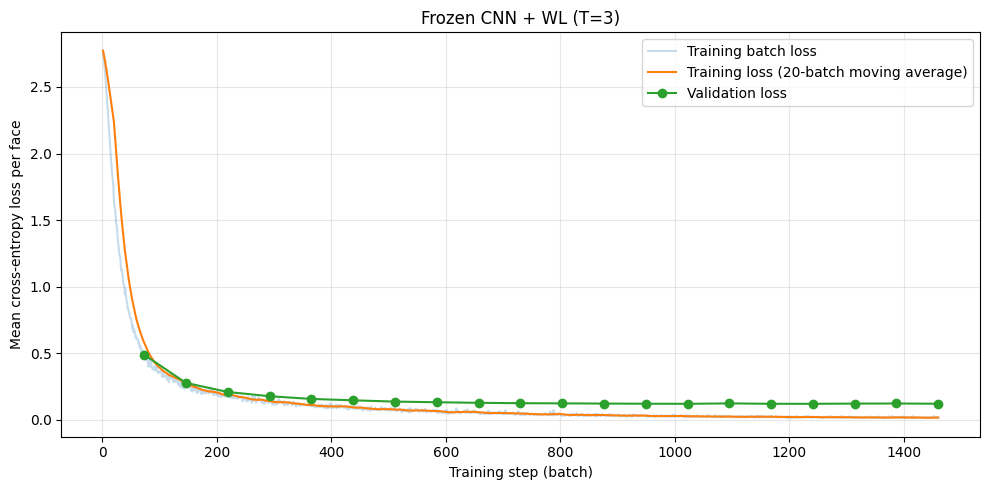

In [17]:
import matplotlib.pyplot as plt
import pandas as pd

batch_log = pd.DataFrame(batch_history)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(batch_log["step"], batch_log["loss"], alpha=0.25, label="Training batch loss")
ax.plot(batch_log["step"], batch_log["loss"].rolling(20, min_periods=1).mean(),
        label="Training loss (20-batch moving average)")
ax.plot([row["step"] for row in history],
        [row["validation_loss"] for row in history], marker="o", label="Validation loss")
ax.set_xlabel("Training step (batch)")
ax.set_ylabel("Mean cross-entropy loss per face")
ax.set_title(f"{training_mode.capitalize()} CNN + WL (T={wl_iterations})")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(run_dir / "loss.png", dpi=150)
plt.show()

### 6.2 Accuracy and per-class IoU for the current run

Saved predictions provide loss, accuracy, and intersection over union (IoU)
for the complete training, validation, and test splits. IoU is
`TP / (TP + FP + FN)`, with counts aggregated over all faces in each split.
Mean IoU gives classes equal weight, includes stock, and excludes zero-union classes.

This cell reads cached predictions without inference. After a kernel restart,
run the imports and configuration cells in section 1, then this cell; encoder
loading and data preparation are not required. All three prediction files from
the selected epoch must be available. Set `report_checkpoint_dir` to inspect
another completed run.

In [18]:
# Choose the saved epoch to analyse.
report_checkpoint_dir = run_dir / f"epoch_{num_epochs:03d}"
for split in SPLITS:
    prediction_path = report_checkpoint_dir / f"{split}_predictions.pt"
    if not prediction_path.is_file():
        raise FileNotFoundError(
            f"Missing {prediction_path}. Run final evaluation for all three splits first."
        )

class_names = {}
for label_file in (DATA_DIR / "labels").glob("*.json"):
    with label_file.open() as file:
        faces = json.load(file)["body"]["faces"]
    for face in faces:
        segment = face["segment"]
        class_names[segment["index"]] = segment["name"]
    if len(class_names) == 16:
        break

class_rows = []
summary_rows = []
for split in SPLITS:
    prediction_path = report_checkpoint_dir / f"{split}_predictions.pt"
    results = torch.load(prediction_path, map_location="cpu", weights_only=True)
    labels = results["labels"].long()
    predictions = results["predictions"].long()
    num_classes = results["probabilities"].shape[1]
    confusion = torch.bincount(
        labels * num_classes + predictions, minlength=num_classes**2
    ).reshape(num_classes, num_classes)
    intersection = confusion.diag()
    union = confusion.sum(1) + confusion.sum(0) - intersection
    # Leave out classes with no true or predicted faces when averaging IoU.
    iou = intersection.double() / union.double().masked_fill(union == 0, float("nan"))
    summary_rows.append({
        "split": split,
        "solids": len(results["sample_ids"]),
        "faces": labels.numel(),
        "loss": results["loss"],
        "accuracy": intersection.sum().item() / labels.numel(),
        "mean_iou": iou.nanmean().item(),
    })
    for index in range(num_classes):
        class_rows.append({
            "split": split, "class_index": index,
            "class_name": class_names.get(index, str(index)),
            "support": confusion[index].sum().item(),
            "intersection": intersection[index].item(),
            "union": union[index].item(), "iou": iou[index].item(),
        })

summary = pd.DataFrame(summary_rows).set_index("split")
per_class_iou = pd.DataFrame(class_rows)
display(summary.style.format({"loss": "{:.4f}", "accuracy": "{:.2%}", "mean_iou": "{:.2%}"}))
display(per_class_iou.pivot(index=["class_index", "class_name"],
                           columns="split", values="iou").style.format("{:.2%}"))
summary.to_csv(report_checkpoint_dir / "iou_summary.csv")
per_class_iou.to_csv(report_checkpoint_dir / "per_class_iou.csv", index=False)

,solids,faces,loss,accuracy,mean_iou
split,,,,,
train,9277,209847,0.0137,99.69%,99.26%
validation,3090,70255,0.1187,95.61%,90.25%
test,3094,69411,0.1218,95.55%,90.43%


,split,test,train,validation
class_index,class_name,,,
0,rectangular_through_slot,99.80%,100.00%,99.78%
1,triangular_through_slot,65.68%,96.03%,65.75%
2,rectangular_passage,79.11%,97.77%,77.72%
3,triangular_passage,83.08%,98.52%,84.92%
4,6sides_passage,99.55%,100.00%,99.42%
5,rectangular_through_step,75.59%,97.28%,72.85%
6,2sides_through_step,86.41%,98.71%,85.60%
7,slanted_through_step,99.93%,100.00%,99.82%
8,rectangular_blind_step,99.06%,100.00%,98.80%


### 6.3 Comparison with geometry-only and WL variants

Completed geometry-only and WL runs are compared using saved predictions.
WL round counts, CNN modes, and run IDs are shown separately. For each variant,
the most recent epoch with both training and validation predictions is selected.
Test scores are included when available at that same epoch, allowing earlier
runs with training and validation exports to remain in the comparison.

This analysis does not select models by validation or test performance. All
reported mean IoU values include stock. The cell can run independently after
a kernel restart and performs no training or inference.

In [19]:
# Compare cached final predictions across all completed variants.
import json
import pandas as pd
import torch
from IPython.display import display
from uvnet_project.load_mfcad import DATA_DIR

project_dir = DATA_DIR.parent.parent
import re
variant_dirs = {"Geometry only": project_dir / "results/baseline_run_01"}
for folder in sorted((project_dir / "results").glob("wl*_run_*")):
    match = re.fullmatch(r"wl(\d+)_(frozen|joint)_run_(\d+)", folder.name)
    if match:
        rounds, mode, run_id = match.groups()
        label = f"{mode.capitalize()} CNN + WL (T={rounds}, run {run_id})"
        variant_dirs[label] = folder
class_names = {}
for label_file in (DATA_DIR / "labels").glob("*.json"):
    with label_file.open() as file:
        faces = json.load(file)["body"]["faces"]
    for face in faces:
        segment = face["segment"]
        class_names[segment["index"]] = segment["name"]
    if len(class_names) == 16:
        break

summary_rows, class_rows = [], []
for variant, directory in variant_dirs.items():
    # Final predictions are written only after training. Use the highest epoch
    # with both splits available, not a partially written final evaluation.
    completed = [folder for folder in directory.glob("epoch_*")
                 if folder.name.removeprefix("epoch_").isdigit()
                 and all((folder / f"{split}_predictions.pt").is_file()
                         for split in ("train", "validation"))]
    if not completed:
        print(f"No completed prediction files yet: {variant}")
        continue
    checkpoint_dir = max(completed, key=lambda folder: int(folder.name.split("_")[-1]))
    epoch = int(checkpoint_dir.name.split("_")[-1])
    available_splits = [split for split in ("train", "validation", "test")
                        if (checkpoint_dir / f"{split}_predictions.pt").is_file()]
    for split in available_splits:
        results = torch.load(checkpoint_dir / f"{split}_predictions.pt",
                             map_location="cpu", weights_only=True)
        labels, predictions = results["labels"].long(), results["predictions"].long()
        num_classes = results["probabilities"].shape[1]
        confusion = torch.bincount(labels * num_classes + predictions,
                                  minlength=num_classes**2).reshape(num_classes, num_classes)
        intersection = confusion.diag()
        support = confusion.sum(1)
        union = support + confusion.sum(0) - intersection
        iou = intersection.double() / union.double().masked_fill(union == 0, float("nan"))
        per_class_accuracy = intersection.double() / support.double().masked_fill(support == 0, float("nan"))
        summary_rows.append(dict(variant=variant, epoch=epoch, split=split,
                                 faces=labels.numel(), loss=results["loss"],
                                 accuracy=intersection.sum().item() / labels.numel(),
                                 mean_iou=iou.nanmean().item()))
        for index in range(num_classes):
            class_rows.append(dict(variant=variant, epoch=epoch, split=split,
                                   class_index=index, class_name=class_names.get(index, str(index)),
                                   support=support[index].item(), iou=iou[index].item(),
                                   accuracy=per_class_accuracy[index].item()))

if summary_rows:
    summary = pd.DataFrame(summary_rows).set_index(["variant", "epoch", "split"])
    per_class_metrics = pd.DataFrame(class_rows)
    display(summary.style.format({"loss": "{:.4f}", "accuracy": "{:.2%}", "mean_iou": "{:.2%}"}))
    print("Per-class IoU (unweighted class mean above, including stock):")
    display(per_class_metrics.pivot(index=["class_index", "class_name"],
                                    columns=["variant", "split"], values="iou").style.format("{:.2%}"))
    summary.to_csv(project_dir / "results/wl_variant_metrics.csv")
    per_class_metrics.to_csv(project_dir / "results/wl_variant_per_class_metrics.csv", index=False)
else:
    print("Run training through final prediction export before comparing metrics.")

Per-class IoU (unweighted class mean above, including stock):


### 6.4 Loss comparison across variants

Epoch-level training and validation losses are plotted from the saved histories
of the geometry-only model and WL variants. Different round counts and training
modes remain separate. Missing runs are skipped, and test scores are not used
to construct training curves. This cell can run independently after a kernel restart.

Saved comparison: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\results\wl_variants_loss.png


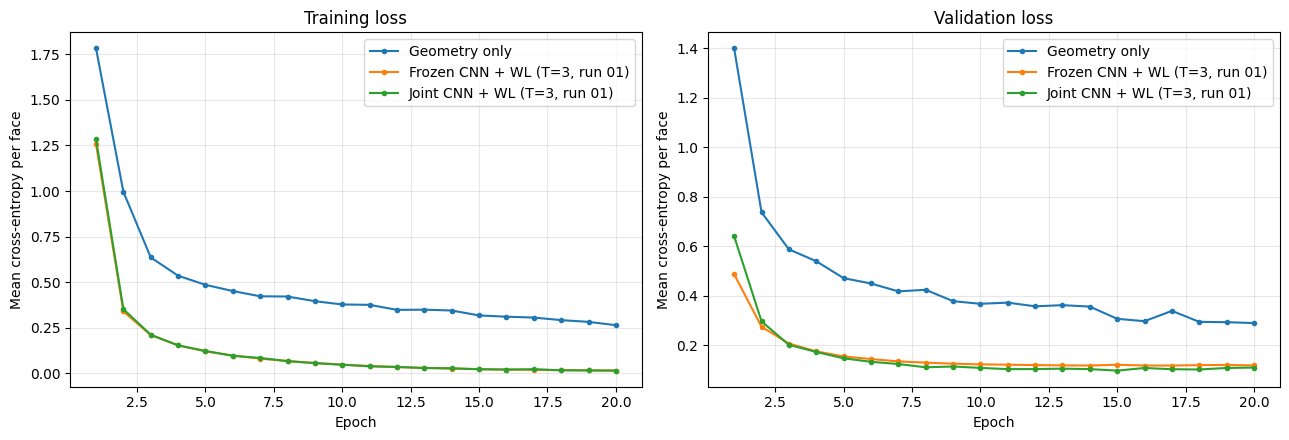

In [20]:
# Comparison from saved histories; no inference or training.
import matplotlib.pyplot as plt
import pandas as pd

import re
from uvnet_project.load_mfcad import DATA_DIR
project_dir = DATA_DIR.parent.parent
variants = {"Geometry only": project_dir / "results/baseline_run_01/history.csv"}
for folder in sorted((project_dir / "results").glob("wl*_run_*")):
    match = re.fullmatch(r"wl(\d+)_(frozen|joint)_run_(\d+)", folder.name)
    if match:
        rounds, mode, run_id = match.groups()
        label = f"{mode.capitalize()} CNN + WL (T={rounds}, run {run_id})"
        variants[label] = folder / "history.csv"
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plotted = 0
for label, path in variants.items():
    if not path.is_file():
        print(f"Not run yet: {label}")
        continue
    frame = pd.read_csv(path)
    if frame.empty:
        continue
    for ax, metric in zip(axes, ("train_loss", "validation_loss")):
        ax.plot(frame["epoch"], frame[metric], marker="o", markersize=3, label=label)
    plotted += 1
for ax, title in zip(axes, ("Training loss", "Validation loss")):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean cross-entropy per face")
    ax.grid(alpha=0.3)
    if plotted:
        ax.legend()
fig.tight_layout()
if plotted:
    comparison_path = project_dir / "results/wl_variants_loss.png"
    fig.savefig(comparison_path, dpi=150)
    print("Saved comparison:", comparison_path)
plt.show()